# 17. S-Matrix Layer Mode Reuse Across Diverse Substrates & Thickness Averaging

## Physical Motivation & Learning Objectives
The modularity of the scattering-matrix method allows pre-computed layer eigenmodes to be reused across varying substrates and active layer thicknesses without re-solving the nanostructure field equations.
In this tutorial:
1. We compute 1D grating modes once.
2. We evaluate absorption across 10 different substrate refractive indices.
3. We average across multiple thicknesses to eliminate Fabry–Pérot interference fringes.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Grating Mode Calculation & Substrate Sweep


In [2]:
wl = 650.0      # nm
period = 600.0  # nm

light = objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0)

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
grating = objects.NanoStruct(
    '1D_array', period, 480.0, height_nm=2330.0,
    inclusion_a=materials.Si_c, background=materials.Air, loss=True,
    lc_bkg=0.01, plt_msh=False
)

sim_sup = superstrate.calc_modes(light)
sim_grt = grating.calc_modes(light, num_BMs=20)

sub_indices = np.linspace(1.0, 4.0, 10)
heights = np.linspace(2200.0, 2400.0, 5)
avg_absorption = []

for n_sub in sub_indices:
    sub = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(n_sub), world_1d=True, loss=False)
    sim_sub = sub.calc_modes(light)
    
    a_h = []
    for h in heights:
        stk = Stack((sim_sub, sim_grt, sim_sup), heights_nm=[h])
        stk.calc_scat(pol='TE')
        a_h.append(float(stk.a_list[-1]))
    avg_absorption.append(np.mean(a_h))


## Thickness-Averaged Absorption vs Substrate Index


<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<ipython-input-1-649f4ab2d063>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  ax.set_xlabel('Substrate Refractive Index $n_{\mathrm{sub}}$', fontsize=11)
<ipython-input-1-649f4ab2d063>:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


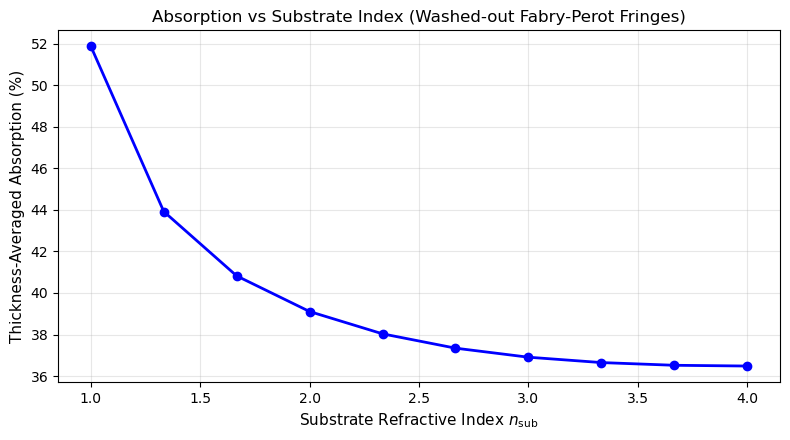

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=100)
ax.plot(sub_indices, np.array(avg_absorption) * 100, 'b-o', lw=2)
ax.set_xlabel('Substrate Refractive Index $n_{\mathrm{sub}}$', fontsize=11)
ax.set_ylabel('Thickness-Averaged Absorption (%)', fontsize=11)
ax.set_title('Absorption vs Substrate Index (Washed-out Fabry-Perot Fringes)', fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Physical Interpretation
- Reusing the nanostructure S-matrix eliminates the computational cost of recalculating internal eigenmodes for every substrate configuration.
- Averaging over multiple heights suppresses sharp coherent interference fringes, modeling incoherent substrate transmission.
